# SD-029 | Last-mile delivery performance
**Sprint 2 — Operations Analytics**
This project asks what happens after an order is placed: whether routes meet delivery promises and where delays or failed handoffs appear. It uses a fully synthetic dataset, so the results demonstrate an analysis method rather than describe a real delivery business.
Questions: How often are completed orders on time? How do route conditions, route distance, rider experience, and delivery events relate to delay? What should an operations analyst inspect next?



## Reference check: inspect and summarize
I compare the generated route scale with the local summary of Amazon Last Mile Routing Research Challenge sequences. It provides broad scale context only; no fresh fetch was made, current availability is not established, and it does not set delivery outcomes.



In [47]:
from pathlib import Path
import pandas as pd

REFERENCE_DIR = Path(__file__).resolve().parent.parent / "reference_data" if "__file__" in globals() else Path("../reference_data")
calibration = pd.read_csv(REFERENCE_DIR / "route_calibration.csv")
calibration.loc[calibration["dataset"] == "SD-029 planned stops", "source"] = "SD-029 synthetic route planned stops"
print(calibration)



                             dataset  \
0  Amazon challenge actual sequences   
1               SD-029 planned stops   

                                              source  route_count  \
0  s3://amazon-last-mile-challenges/almrrc2021/al...         6112   
1               SD-029 synthetic route planned stops           48   

   min_sequence_entries  median_sequence_entries  max_sequence_entries  
0                    33                    151.0                   238  
1                    10                     10.0                    10  


## Compare the reference with the synthetic design
[OBSERVED] The local route summary records 6,112 Amazon training route sequences, with 33–238 sequence entries per route (median 151). SD-029 has 48 synthetic routes with ten planned stops each. [DERIVED] This is a scale comparison only because sequence entries may not be equivalent to planned stops; ten stops remains a teaching assumption.



## Note limitations, then proceed
[LIMITATION] The local summary is based on a challenge-specific training input and does not represent all delivery businesses; no current reachability is established. Sequence entries and planned stops may differ, and the reference does not validate SD-029 numeric route, rider, weather, attempt, or delay assumptions. I use the generated sample for the analysis.



## 1. Load the five CSV tables
I examine the five generated tables before comparing completion, on-time delivery, and delay.



In [48]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path(__file__).resolve().parents[1] / "data" if "__file__" in globals() else Path("../data")



In [49]:
orders = pd.read_csv(data_dir / "orders.csv", parse_dates=["ordered_at", "promised_by"])
deliveries = pd.read_csv(data_dir / "deliveries.csv", parse_dates=["dispatch_time", "delivered_at"])
riders = pd.read_csv(data_dir / "riders.csv")
routes = pd.read_csv(data_dir / "routes.csv", parse_dates=["route_date"])
events = pd.read_csv(data_dir / "delivery_events.csv", parse_dates=["event_time"])



In [50]:
table_sizes = pd.DataFrame({
    "table": ["orders", "deliveries", "riders", "routes", "delivery_events"],
    "rows": [len(orders), len(deliveries), len(riders), len(routes), len(events)],
})
table_sizes



,table,rows
0,orders,480
1,deliveries,480
2,riders,16
3,routes,48
4,delivery_events,2000


In [51]:
# Check keys and relationships before joining the tables.
assert orders['order_id'].is_unique
assert deliveries['order_id'].is_unique
assert orders['route_id'].isin(routes['route_id']).all()
assert routes['rider_id'].isin(riders['rider_id']).all()
assert events['order_id'].isin(orders['order_id']).all()



In [52]:
delivery_view = deliveries.merge(
    orders[['order_id', 'order_date', 'service_zone', 'stop_sequence', 'promised_by']],
    on='order_id',
)
delivery_view['delay_minutes'] = pd.to_numeric(delivery_view['delay_minutes'], errors='coerce')
completed = delivery_view[delivery_view['delivery_status'] == 'delivered'].copy()
completed['on_time'] = completed['delay_minutes'] <= 0
print(f"Orders: {len(orders)} | completed deliveries: {len(completed)} | not completed: {len(delivery_view) - len(completed)}")
print(f"Date range: {orders['order_date'].min()} to {orders['order_date'].max()}")



Orders: 480 | completed deliveries: 479 | not completed: 1
Date range: 2025-05-01 to 2025-05-24


## 2. Overall delivery performance
Delay is the number of minutes between the delivered timestamp and the promised time. Negative values mean early delivery. The on-time rate uses completed deliveries only; a returned order is not treated as on-time or late because it has no completed delivery timestamp.



In [53]:
performance = pd.DataFrame({
    'measure': ['Completed delivery rate', 'On-time rate among completed', 'Median delay (minutes)', '90th percentile delay (minutes)', 'Returned orders'],
    'value': [
        len(completed) / len(delivery_view),
        completed['on_time'].mean(),
        completed['delay_minutes'].median(),
        completed['delay_minutes'].quantile(0.90),
        (delivery_view['delivery_status'] == 'returned_to_depot').sum(),
    ],
})
performance



,measure,value
0,Completed delivery rate,0.997917
1,On-time rate among completed,0.108559
2,Median delay (minutes),19.000000
3,90th percentile delay (minutes),44.000000
4,Returned orders,1.000000


## 3. Delay patterns by day and service zone
Daily rates can move with the small number of routes in this synthetic sample. Zone comparisons are descriptive; the dataset is not a controlled experiment.



In [54]:
daily = completed.groupby('order_date').agg(
    on_time_rate=('on_time', 'mean'),
    median_delay=('delay_minutes', 'median'),
    completed_orders=('order_id', 'count'),
).reset_index()
zone_summary = completed.groupby('service_zone').agg(
    on_time_rate=('on_time', 'mean'),
    median_delay=('delay_minutes', 'median'),
    completed_orders=('order_id', 'count'),
).sort_values('on_time_rate')
print(zone_summary.round(2))



              on_time_rate  median_delay  completed_orders
service_zone                                              
Outer Ring            0.02          32.5                40
East                  0.06          19.0                79
North                 0.09          21.0               100
West                  0.14          23.0               100
Central               0.14          17.5                70
South                 0.14          14.5                90


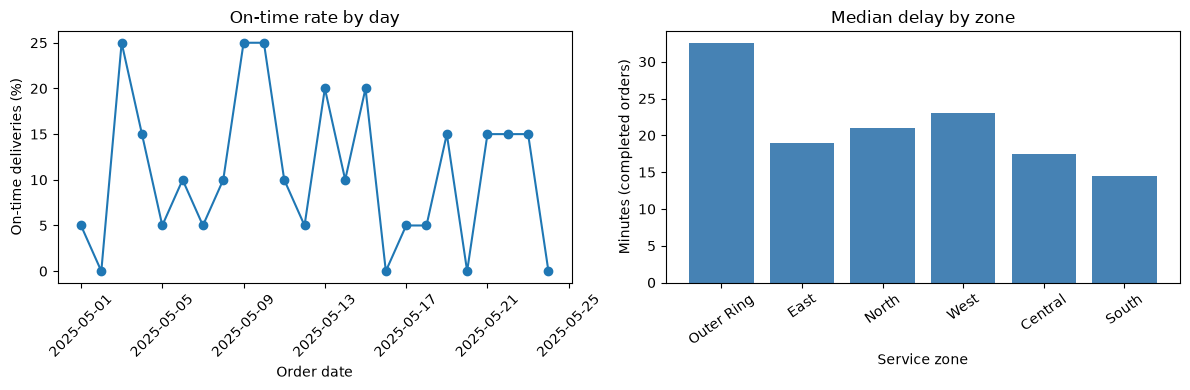

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(pd.to_datetime(daily['order_date']), daily['on_time_rate'] * 100, marker='o')
axes[0].set(title='On-time rate by day', ylabel='On-time deliveries (%)', xlabel='Order date')
axes[0].tick_params(axis='x', rotation=45)
axes[1].bar(zone_summary.index, zone_summary['median_delay'], color='steelblue')
axes[1].set(title='Median delay by zone', ylabel='Minutes (completed orders)', xlabel='Service zone')
axes[1].tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()



## 4. Route conditions and distance
Join completed-order metrics to route conditions. Compare actual with planned route distance and inspect traffic alongside route median delay. A longer route or a busier route may also serve a different zone, so these patterns do not establish cause.



In [56]:
route_delivery = completed.groupby('route_id').agg(
    median_delay=('delay_minutes', 'median'),
    on_time_rate=('on_time', 'mean'),
    completed_orders=('order_id', 'count'),
).reset_index()
route_summary = routes.merge(route_delivery, on='route_id')
route_summary['distance_over_plan_km'] = route_summary['actual_distance_km'] - route_summary['planned_distance_km']
print(route_summary[['route_id', 'service_zone', 'traffic_index', 'rain_mm', 'planned_distance_km', 'actual_distance_km', 'median_delay', 'on_time_rate']].head(10).round(2))



  route_id service_zone  traffic_index  rain_mm  planned_distance_km  \
0   RT-001         West           1.53      2.0                 11.0   
1   RT-002      Central           1.35      2.0                 10.3   
2   RT-003        North           1.21     18.0                  9.1   
3   RT-004        North           1.21     10.0                 11.3   
4   RT-005         West           1.43      0.0                 12.8   
5   RT-006         West           0.87      2.0                 12.3   
6   RT-007   Outer Ring           1.09     18.0                 23.9   
7   RT-008        North           0.90      0.0                  8.4   
8   RT-009         West           1.49     10.0                 10.4   
9   RT-010         East           1.15     10.0                  7.3   

   actual_distance_km  median_delay  on_time_rate  
0                12.7          33.5           0.0  
1                11.5          14.0           0.1  
2                11.1          28.5           0.0  

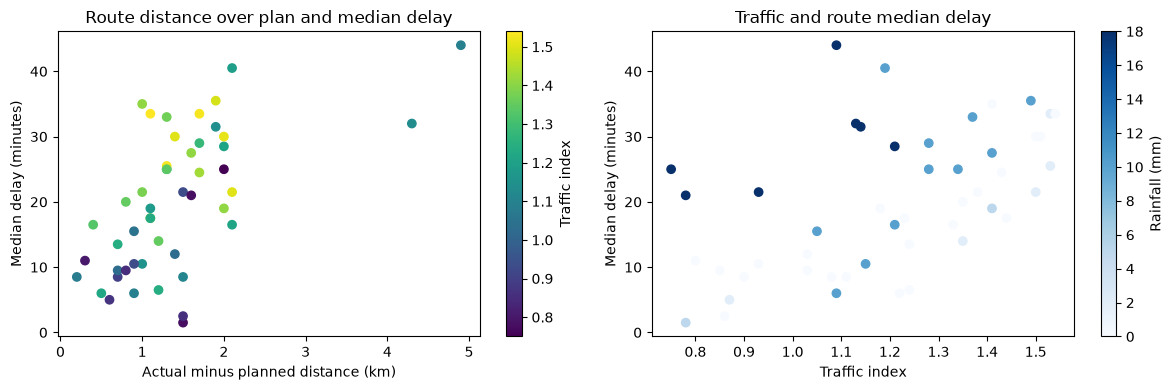

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
points = axes[0].scatter(route_summary['distance_over_plan_km'], route_summary['median_delay'], c=route_summary['traffic_index'], cmap='viridis')
axes[0].set(title='Route distance over plan and median delay', xlabel='Actual minus planned distance (km)', ylabel='Median delay (minutes)')
fig.colorbar(points, ax=axes[0], label='Traffic index')
points = axes[1].scatter(route_summary['traffic_index'], route_summary['median_delay'], c=route_summary['rain_mm'], cmap='Blues')
axes[1].set(title='Traffic and route median delay', xlabel='Traffic index', ylabel='Median delay (minutes)')
fig.colorbar(points, ax=axes[1], label='Rainfall (mm)')
plt.tight_layout()
plt.show()



## 5. Rider-level comparison
Rider averages are useful for finding questions to investigate, not for ranking workers. Each rider has only a few assigned routes, and zone, traffic, rain, and route difficulty are not fully controlled. The table includes delivery counts to make the sample size visible.



In [58]:
rider_summary = completed.groupby('rider_id').agg(
    completed_orders=('order_id', 'count'),
    on_time_rate=('on_time', 'mean'),
    median_delay=('delay_minutes', 'median'),
).join(riders.set_index('rider_id')[['experience_months', 'vehicle_type']]).sort_values('median_delay')
print(rider_summary.round(2))



          completed_orders  on_time_rate  median_delay  experience_months  \
rider_id                                                                    
R-011                   30          0.13          11.0                 46   
R-006                   30          0.20          12.0                 39   
R-013                   30          0.17          12.5                 28   
R-014                   30          0.10          12.5                 44   
R-004                   30          0.17          14.5                 46   
R-010                   30          0.10          16.0                 44   
R-002                   30          0.07          17.5                 34   
R-005                   30          0.13          18.5                 27   
R-008                   30          0.13          18.5                 28   
R-015                   30          0.07          22.5                 25   
R-001                   30          0.17          23.0                 31   

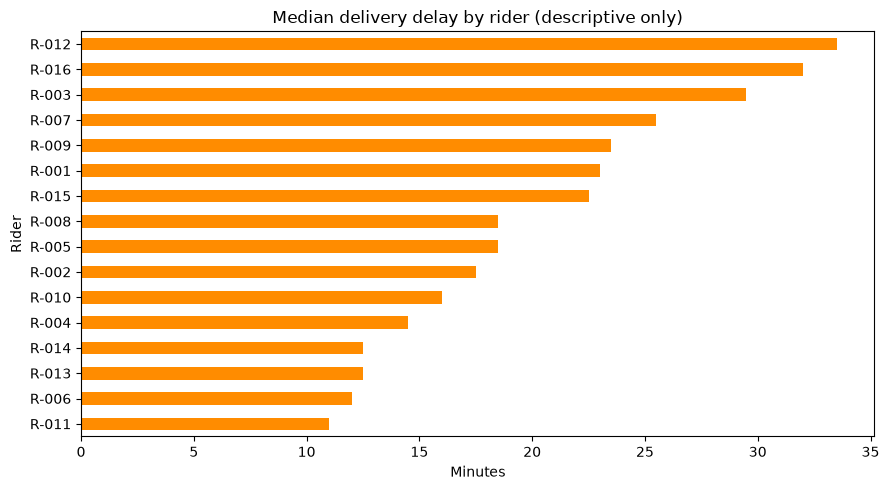

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))
rider_summary['median_delay'].sort_values().plot(kind='barh', ax=ax, color='darkorange')
ax.set(title='Median delivery delay by rider (descriptive only)', xlabel='Minutes', ylabel='Rider')
plt.tight_layout()
plt.show()



## 6. Delivery events and edge cases
The event records show the delivery journey as well as the final status. [OBSERVED] `ORD-0001` was delivered 185 minutes late after two failed attempts; `ORD-0480` was returned after two failed attempts and has no delivery timestamp.



In [60]:
event_counts = events['event_type'].value_counts()
print(event_counts.rename_axis('event_type').reset_index(name='event_rows'))

attempt_summary = delivery_view.groupby('service_zone').agg(
    orders=('order_id', 'count'),
    orders_with_failed_attempt=('failed_attempts', lambda values: (values > 0).sum()),
    returned_orders=('delivery_status', lambda values: (values == 'returned_to_depot').sum()),
).reset_index()
attempt_summary['failed_attempt_share'] = attempt_summary['orders_with_failed_attempt'] / attempt_summary['orders']
print(attempt_summary.round(2))



          event_type  event_rows
0       order_placed         480
1     route_assigned         480
2   out_for_delivery         480
3          delivered         479
4     attempt_failed          40
5        reattempted          40
6  returned_to_depot           1
  service_zone  orders  orders_with_failed_attempt  returned_orders  \
0      Central      70                           4                0   
1         East      80                           8                1   
2        North     100                           3                0   
3   Outer Ring      40                           8                0   
4        South      90                           4                0   
5         West     100                           5                0   

   failed_attempt_share  
0                  0.06  
1                  0.10  
2                  0.03  
3                  0.20  
4                  0.04  
5                  0.05  


In [61]:
edge_case_ids = ['ORD-0001', 'ORD-0480']
edge_case_view = delivery_view[delivery_view['order_id'].isin(edge_case_ids)][
    ['order_id', 'service_zone', 'delivery_status', 'delay_minutes', 'failed_attempts', 'exception_reason', 'delivered_at']
].sort_values('order_id')
print(edge_case_view)



     order_id service_zone    delivery_status  delay_minutes  failed_attempts  \
0    ORD-0001         West          delivered          185.0                2   
479  ORD-0480         East  returned_to_depot            NaN                2   

          exception_reason        delivered_at  
0        restricted_access 2025-05-01 11:28:00  
479  recipient_unavailable                 NaT  


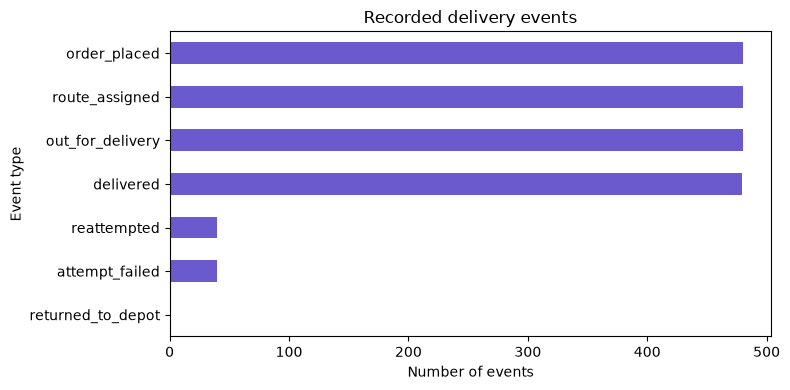

In [62]:
fig, ax = plt.subplots(figsize=(8, 4))
event_counts.sort_values().plot(kind='barh', ax=ax, color='slateblue')
ax.set(title='Recorded delivery events', xlabel='Number of events', ylabel='Event type')
plt.tight_layout()
plt.show()



## 7. Operational readout
I would validate the promise-time definition, compare similar routes and shifts, and review event notes with dispatch teams. Rider summaries are descriptive context, not individual performance rankings.
### Limitations
- All records and relationships are synthetic and generated from simple assumptions.
- Only 24 operating days, 48 routes, and 16 riders are represented. Patterns may be unstable at this size.
- Traffic, rain, distance, experience, and attempted delivery are related by the generator; observed associations are not causal effects.
- Returned orders have no completed-delivery delay and are excluded from on-time and delay summaries, but remain in the completion-rate denominator.
- Events are a simplified milestone log and do not model GPS traces or exact stop-level travel times.

